## Governance / ESG vs. ROE and Beta

## Setup

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

sns.set_style('whitegrid')


## Load data

In [2]:
df = pd.read_csv('cleaned_data.csv')

target_cols = ['Governance Pillar Score (FY0)', 'ESG Score (FY0)']
perf_cols   = ['Beta 5 Year', 'ROE 5 YR Avg']

df.head()


,Identifier (RIC),Company Name,Market Cap (Billions),Beta 5 Year,Governance Pillar Score (FY0),ESG Score (FY0),ROE 5 YR Avg
0,NVDA.OQ,NVIDIA Corp,4925.43,2.22,85.51,74.05,66.85
1,AAPL.OQ,Apple Inc,4660.44,1.09,89.08,71.07,149.64
2,GOOGL.OQ,Alphabet Inc,4281.56,1.24,78.30,79.07,23.02
3,MSFT.OQ,Microsoft Corp,2904.44,1.12,92.54,87.50,36.99
4,AMZN.OQ,Amazon.com Inc,2660.34,1.47,50.45,69.04,16.83


## Clean data
Force numeric types, then check whether missing scores are randomly distributed (informative missingness would bias the sample before any analysis starts).

In [3]:
for col in target_cols + perf_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Flag rows with any missing value in the columns we need
df['_is_missing'] = df[target_cols + perf_cols].isna().any(axis=1)

print(f"Total companies: {len(df)}")
print(f"Rows with complete data: {(~df['_is_missing']).sum()}")
print(f"Rows dropped for missing data: {df['_is_missing'].sum()}  ({df['_is_missing'].mean():.1%})")

# Check whether dropped companies skew toward smaller / larger market cap
# (a proxy check for whether the drop is random or systematic)
print("\nMedian market cap — kept vs dropped:")
print(df.groupby('_is_missing')['Market Cap (Billions)'].median())

df_clean = df.dropna(subset=target_cols + perf_cols).copy()
df_clean = df_clean.drop(columns='_is_missing')
print(f"\nFinal clean sample size: {len(df_clean)}")


Total companies: 1541
Rows with complete data: 1076
Rows dropped for missing data: 465  (30.2%)

Median market cap — kept vs dropped:
_is_missing
False    15.475
True     12.660
Name: Market Cap (Billions), dtype: float64

Final clean sample size: 1076


## Outlier treatment
`ROE 5 YR Avg` contains extreme values (companies with near-zero or negative book equity produce ROE figures in the thousands of percent). So we **winsorize** (cap at the 1st/99th percentile) rather than delete them. `Beta 5 Year` is left untouched — its range is already sane.

In [4]:
print("ROE 5 YR Avg — before winsorizing:")
print(df_clean['ROE 5 YR Avg'].describe()[['mean', 'std', 'min', 'max']])

lo, hi = df_clean['ROE 5 YR Avg'].quantile([0.01, 0.99])
df_clean['ROE_w'] = df_clean['ROE 5 YR Avg'].clip(lo, hi)

print(f"\nWinsorize bounds (1st/99th pct): [{lo:.2f}, {hi:.2f}]")
print("\nROE 5 YR Avg — after winsorizing:")
print(df_clean['ROE_w'].describe()[['mean', 'std', 'min', 'max']])

# Beta sanity check — confirm it does NOT need winsorizing
print("\nBeta 5 Year range (sanity check, no treatment needed):")
print(df_clean['Beta 5 Year'].describe()[['mean', 'std', 'min', 'max']])


ROE 5 YR Avg — before winsorizing:
mean       66.870455
std      1800.341451
min     -2283.870000
max     58819.460000
Name: ROE 5 YR Avg, dtype: float64

Winsorize bounds (1st/99th pct): [-328.54, 238.30]

ROE 5 YR Avg — after winsorizing:
mean     12.919656
std      61.844257
min    -328.542500
max     238.302500
Name: ROE_w, dtype: float64

Beta 5 Year range (sanity check, no treatment needed):
mean    1.039703
std     0.601728
min    -1.250000
max     5.000000
Name: Beta 5 Year, dtype: float64


## Correlation: Governance / ESG vs. Beta and ROE
Pearson on raw data, Pearson on winsorized ROE, and Spearman (rank-based, naturally outlier-robust) are all reported side by side. If Pearson-raw disagrees sharply with the other two, that is itself a sign the raw correlation was distorted by outliers rather than reflecting a real relationship.

In [5]:
perf_cols_analysis = ['Beta 5 Year', 'ROE_w']   # use winsorized ROE from here on

results = []
for target in target_cols:
    for perf in perf_cols_analysis:
        raw_perf = 'ROE 5 YR Avg' if perf == 'ROE_w' else perf
        r_raw, _  = pearsonr(df_clean[target], df_clean[raw_perf])
        r_wins, _ = pearsonr(df_clean[target], df_clean[perf])
        r_sp, _   = spearmanr(df_clean[target], df_clean[perf])
        results.append({
            'Score': target,
            'Metric': raw_perf,
            'Pearson (raw)': round(r_raw, 3),
            'Pearson (winsorized)': round(r_wins, 3),
            'Spearman': round(r_sp, 3),
        })

corr_table = pd.DataFrame(results)
corr_table


,Score,Metric,Pearson (raw),Pearson (winsorized),Spearman
0,Governance Pillar Score (FY0),Beta 5 Year,-0.177,-0.177,-0.116
1,Governance Pillar Score (FY0),ROE 5 YR Avg,-0.004,0.102,0.095
2,ESG Score (FY0),Beta 5 Year,-0.196,-0.196,-0.125
3,ESG Score (FY0),ROE 5 YR Avg,0.037,0.154,0.167


## Quintile segmentation
Companies are ranked and split into 5 equal-sized groups (Q1 = worst-scoring 20%, Q5 = best-scoring 20%) **separately for Governance and for ESG** — a company's Governance quintile and ESG quintile can differ. This replaces the fixed Top 50 / 51-100 / 101-500 cuts, which mixed segment size with an arbitrary rank cutoff.

In [6]:
df_clean['Governance_Quintile'] = pd.qcut(
    df_clean['Governance Pillar Score (FY0)'], 5,
    labels=['Q1 (Lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (Highest)']
)
df_clean['ESG_Quintile'] = pd.qcut(
    df_clean['ESG Score (FY0)'], 5,
    labels=['Q1 (Lowest)', 'Q2', 'Q3', 'Q4', 'Q5 (Highest)']
)

print("Companies per Governance quintile:")
print(df_clean['Governance_Quintile'].value_counts().sort_index())


Companies per Governance quintile:
Governance_Quintile
Q1 (Lowest)     216
Q2              215
Q3              215
Q4              215
Q5 (Highest)    215
Name: count, dtype: int64


## Bar charts — mean AND median per quintile
Median is shown alongside mean since a single extreme company can still pull a quintile's mean even after winsorizing.

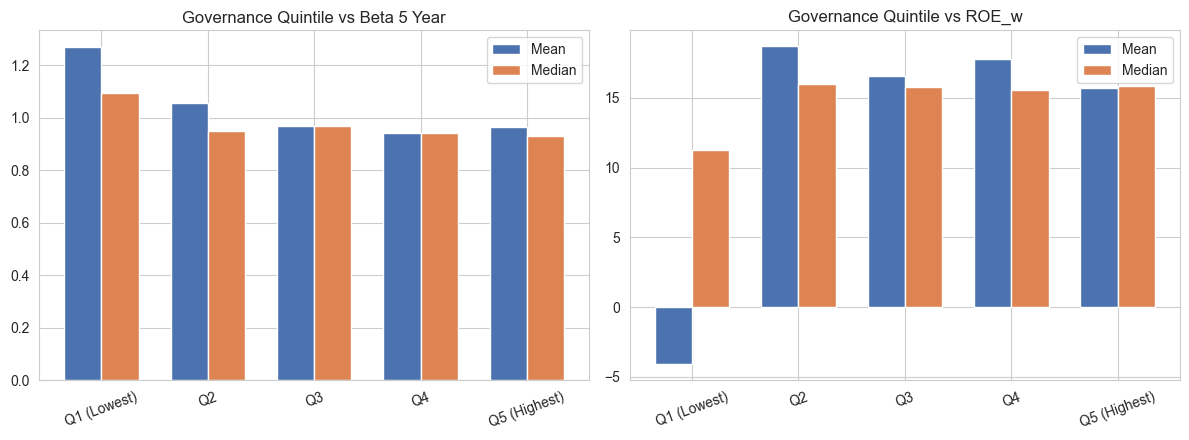

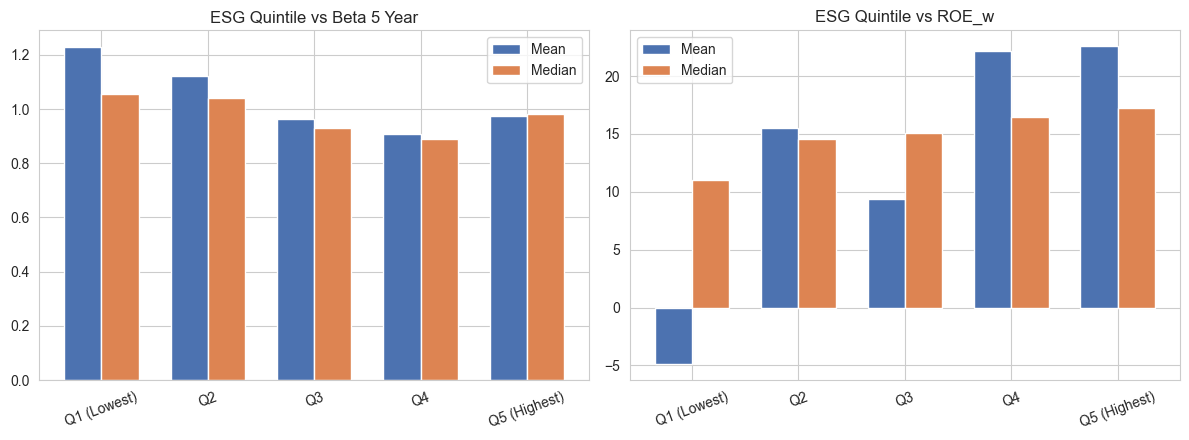

In [7]:
def quintile_bar(df, quintile_col, score_label):
    summary = df.groupby(quintile_col, observed=True)[['Beta 5 Year', 'ROE_w']].agg(['mean', 'median'])
    summary.columns = ['_'.join(c) for c in summary.columns]
    summary = summary.reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, metric in zip(axes, ['Beta 5 Year', 'ROE_w']):
        x = np.arange(len(summary))
        width = 0.35
        ax.bar(x - width/2, summary[f'{metric}_mean'], width, label='Mean', color='#4C72B0')
        ax.bar(x + width/2, summary[f'{metric}_median'], width, label='Median', color='#DD8452')
        ax.set_xticks(x)
        ax.set_xticklabels(summary[quintile_col], rotation=20)
        ax.set_title(f'{score_label} Quintile vs {metric}')
        ax.legend()
    plt.tight_layout()
    plt.show()
    return summary

gov_summary = quintile_bar(df_clean, 'Governance_Quintile', 'Governance')
esg_summary = quintile_bar(df_clean, 'ESG_Quintile', 'ESG')


## Scatter plots with regression line (supplementary view)
Kept for completeness, but treat the quintile bar charts and box plots as the primary evidence — a single scatter/regression line is more easily swayed by a handful of points than a bucketed comparison.

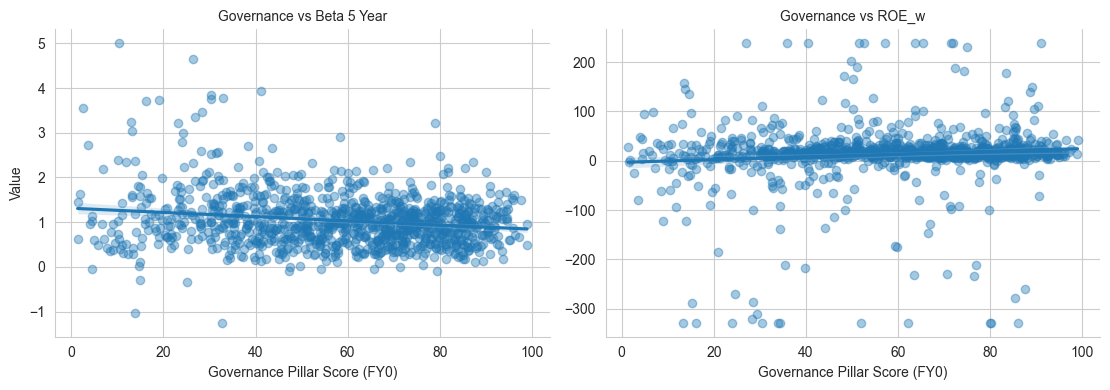

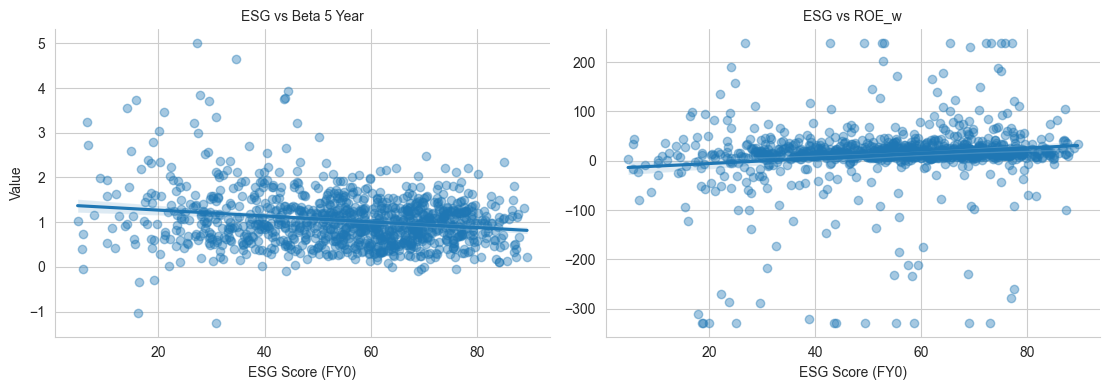

In [8]:
df_long_gov = df_clean.melt(
    id_vars=['Governance Pillar Score (FY0)'],
    value_vars=['Beta 5 Year', 'ROE_w'],
    var_name='Metric', value_name='Value'
)
g = sns.lmplot(data=df_long_gov, x='Governance Pillar Score (FY0)', y='Value',
               col='Metric', col_wrap=2, height=4, aspect=1.4,
               scatter_kws={'alpha': 0.4}, facet_kws={'sharey': False})
g.set_titles("Governance vs {col_name}")
plt.show()

df_long_esg = df_clean.melt(
    id_vars=['ESG Score (FY0)'],
    value_vars=['Beta 5 Year', 'ROE_w'],
    var_name='Metric', value_name='Value'
)
g = sns.lmplot(data=df_long_esg, x='ESG Score (FY0)', y='Value',
               col='Metric', col_wrap=2, height=4, aspect=1.4,
               scatter_kws={'alpha': 0.4}, facet_kws={'sharey': False})
g.set_titles("ESG vs {col_name}")
plt.show()


## Box plots by quintile — robustness check
Shows the full spread (median, IQR, remaining outliers) per quintile rather than a single average, so a pattern seen in Section 7 can be confirmed as broad-based rather than driven by a few companies.

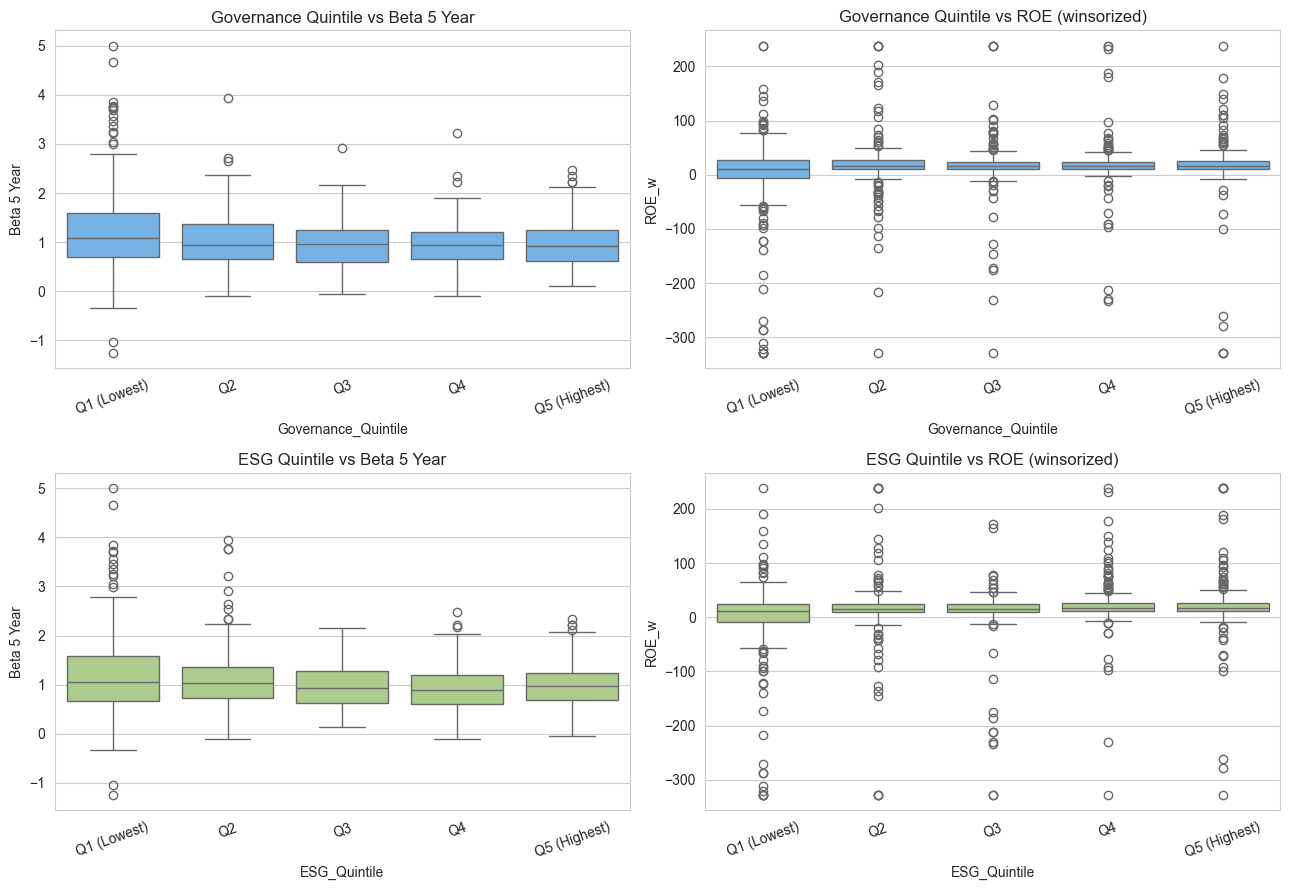

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.boxplot(data=df_clean, x='Governance_Quintile', y='Beta 5 Year', ax=axes[0,0], color='#64B5F6')
axes[0,0].set_title('Governance Quintile vs Beta 5 Year')

sns.boxplot(data=df_clean, x='Governance_Quintile', y='ROE_w', ax=axes[0,1], color='#64B5F6')
axes[0,1].set_title('Governance Quintile vs ROE (winsorized)')

sns.boxplot(data=df_clean, x='ESG_Quintile', y='Beta 5 Year', ax=axes[1,0], color='#AED581')
axes[1,0].set_title('ESG Quintile vs Beta 5 Year')

sns.boxplot(data=df_clean, x='ESG_Quintile', y='ROE_w', ax=axes[1,1], color='#AED581')
axes[1,1].set_title('ESG Quintile vs ROE (winsorized)')

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


## Summary Tables

In [10]:
print("=== Governance Quintile Summary ===")
print(gov_summary.to_string(index=False))
print("\n=== ESG Quintile Summary ===")
print(esg_summary.to_string(index=False))
print("\n=== Correlation Table ===")
print(corr_table.to_string(index=False))


=== Governance Quintile Summary ===
Governance_Quintile  Beta 5 Year_mean  Beta 5 Year_median  ROE_w_mean  ROE_w_median
        Q1 (Lowest)          1.268750               1.095   -4.090185        11.225
                 Q2          1.056233               0.950   18.688767        15.990
                 Q3          0.968651               0.970   16.545465        15.790
                 Q4          0.939721               0.940   17.807512        15.570
       Q5 (Highest)          0.964093               0.930   15.725837        15.860

=== ESG Quintile Summary ===
ESG_Quintile  Beta 5 Year_mean  Beta 5 Year_median  ROE_w_mean  ROE_w_median
 Q1 (Lowest)          1.228380               1.055   -4.904433        11.055
          Q2          1.122372               1.040   15.513174        14.590
          Q3          0.964884               0.930    9.353233        15.110
          Q4          0.907163               0.890   22.140884        16.490
Q5 (Highest)          0.974837               